# Lab: Histogram Manipulation in Image Processing

Welcome to this lab! Today we will explore how to manipulate the contrast and color distributions of images using their histograms. Histograms represent the frequency of pixel intensities in an image. By altering these frequencies, we can drastically improve image quality or apply creative color grading.

We will cover three core algorithms, implementing each from scratch (to understand the math) and using `scikit-image` (for production-level speed):
1. **Histogram (Contrast) Stretching**
2. **Histogram Equalization**
3. **Histogram Matching (Color Grading)**

Let's start by importing our libraries and defining a helper function to visualize our results.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import exposure, data, io, color
import urllib.request

# Helper function to plot an image and its histogram side-by-side
def plot_img_and_hist(image, title, bins=256):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Plot Image
    if len(image.shape) == 2:
        axes[0].imshow(image, cmap='gray', vmin=0, vmax=255)
    else:
        axes[0].imshow(image)
    axes[0].set_title(title)
    axes[0].axis('off')

    # Plot Histogram
    if len(image.shape) == 2:
        axes[1].hist(image.ravel(), bins=bins, color='black', alpha=0.7)
    else:
        colors = ['red', 'green', 'blue']
        for i, c in enumerate(colors):
            axes[1].hist(image[:, :, i].ravel(), bins=bins, color=c, alpha=0.5)

    axes[1].set_title('Histogram')
    axes[1].set_xlim([0, 256])

    plt.tight_layout()
    plt.show()

---
## 1. Histogram (Contrast) Stretching

**Concept:** Contrast stretching (or normalization) is a linear transformation that "stretches" the range of pixel intensities to span the full possible range (usually 0 to 255). It is highly effective for images that look washed out or lack deep blacks and bright whites.

**The Math:**
$$I_{out} = \frac{I_{in} - I_{min_{old}}}{I_{max_{old}} - I_{min_{old}}} \times I_{max_{new}} + I_{min_{new}}$$

Where $I_{min}$ and $I_{max}$ are the minimum and maximum pixel values present in the original image.

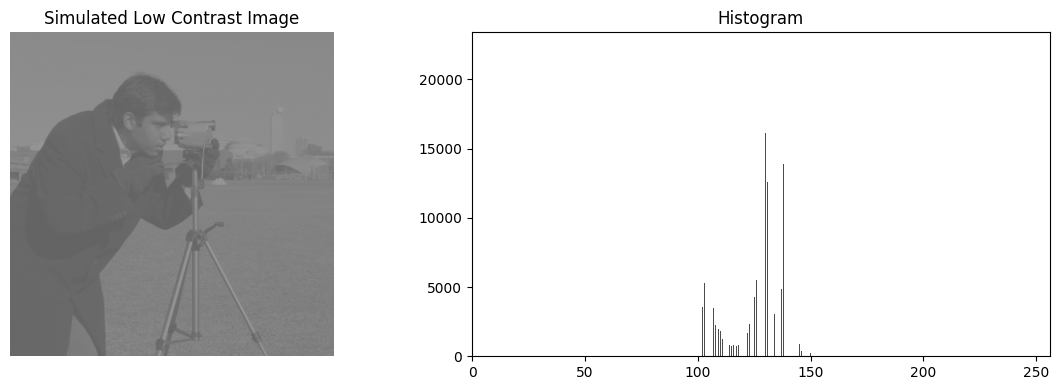

Original Min: 100, Original Max: 150


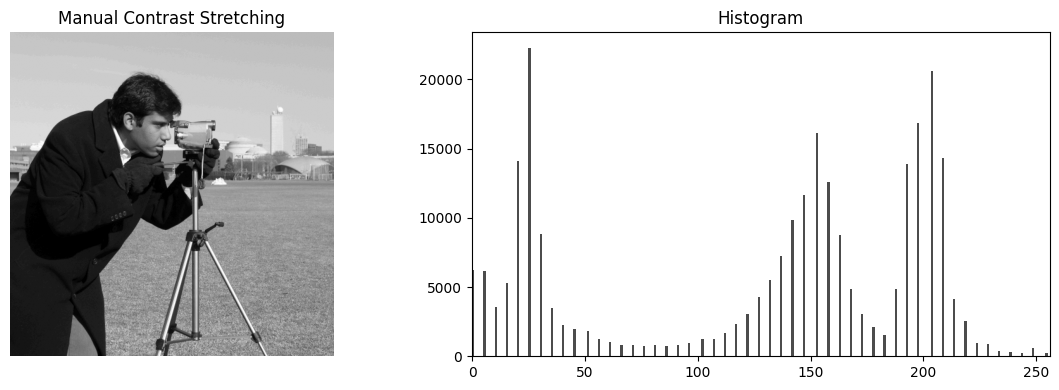

Stretched Min: 0, Stretched Max: 255


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import exposure, data

# ==========================================
# 1. SETUP: Create a truly low-contrast image
# ==========================================
# We start with a crisp image
img_original = data.camera()

# Artificially compress the dynamic range to a narrow band (e.g., 100 to 150)
# This perfectly simulates a foggy, washed-out, or poorly exposed photograph.
img_low_contrast = (img_original.astype(float) / 255.0) * 50.0 + 100.0
img_low_contrast = img_low_contrast.astype(np.uint8)

plot_img_and_hist(img_low_contrast, "Simulated Low Contrast Image")

# ==========================================
# 2. MANUAL IMPLEMENTATION
# ==========================================
def manual_contrast_stretch(img, new_min, new_max):
    img_min = img.min()
    img_max = img.max()

    print(f"Original Min: {img_min}, Original Max: {img_max}")

    # Apply the formula (ensure float for division, then cast back to uint8)
    stretched = (img.astype(float) - img_min) / (img_max - img_min) * new_max + new_min
    return stretched.astype(np.uint8)

img_stretched_manual = manual_contrast_stretch(img_low_contrast, 0, 255)
plot_img_and_hist(img_stretched_manual, "Manual Contrast Stretching")
print(f"Stretched Min: {img_stretched_manual.min()}, Stretched Max: {img_stretched_manual.max()}")

# ==========================================
# 3. SKIMAGE IMPLEMENTATION
# ==========================================
# rescale_intensity stretches the histogram to the out_range
img_stretched_skimage = exposure.rescale_intensity(img_low_contrast, out_range=(0, 255))
plot_img_and_hist(img_stretched_skimage, "Skimage Contrast Stretching")

---
## 2. Histogram Equalization

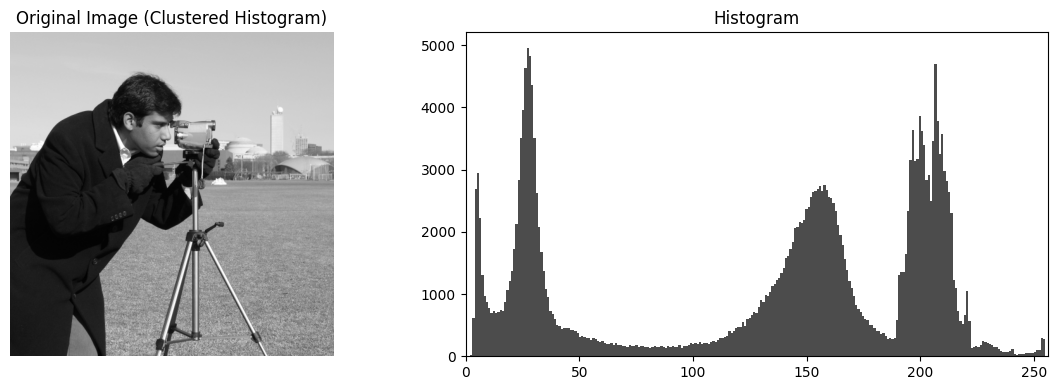

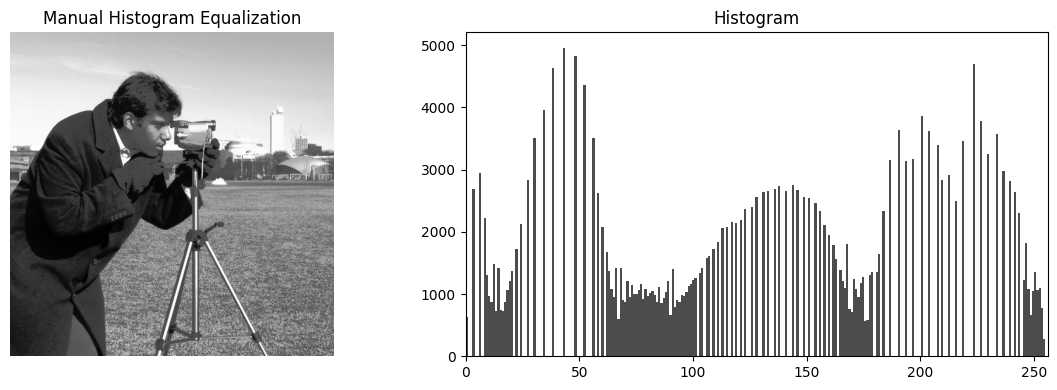

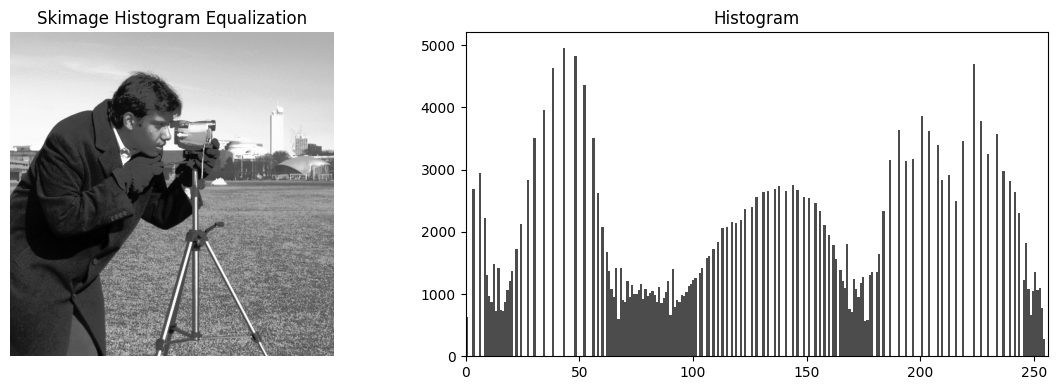

In [ ]:
# Load an image with poor exposure distribution
img_unequalized = data.camera()

plot_img_and_hist(img_unequalized, "Original Image (Clustered Histogram)")

# ==========================================
# 1. MANUAL IMPLEMENTATION
# ==========================================
def manual_histogram_equalization(img):
    # 1. Calculate the histogram
    hist, bins = np.histogram(img.flatten(), 256, [0, 256])

    # 2. Calculate the Probalbility Distribution Function (PDF)
    pdf = hist/len(img.flatten())

    # 3. Calculate the Cumulative Distribution Function (CDF)
    cdf = pdf.cumsum()

    # 4. Multiply cdf by L-1
    cdf_m = cdf * (len(pdf) - 1)

    # 4. convert to integers (approximate)
    map_to_s = cdf_m.astype('uint8')

    # 6. Map the original pixels to their new equalized values
    img_equalized = map_to_s[img]

    return img_equalized

img_eq_manual = manual_histogram_equalization(img_unequalized)
plot_img_and_hist(img_eq_manual, "Manual Histogram Equalization")

# ==========================================
# 2. SKIMAGE IMPLEMENTATION
# ==========================================
# skimage returns float values [0, 1], so we multiply by 255
img_eq_skimage = exposure.equalize_hist(img_unequalized)
img_eq_skimage = (img_eq_skimage * 255).astype(np.uint8)
plot_img_and_hist(img_eq_skimage, "Skimage Histogram Equalization")

---
## 3. Histogram Matching (The "Blade Runner" Effect)

**Concept:**
What if we don't want a flat histogram, but rather want our image to adopt the color characteristics of *another* image? Histogram matching (or specification) modifies the image so its CDF matches the CDF of a reference image.

When applied to the Red, Green, and Blue channels independently, this acts as an incredibly powerful color-grading tool. We can take a normal daylight photo and match it to the neon-drenched cyan/magenta palette of *Blade Runner 2049* or the high-contrast orange/teal of *Mad Max: Fury Road*.

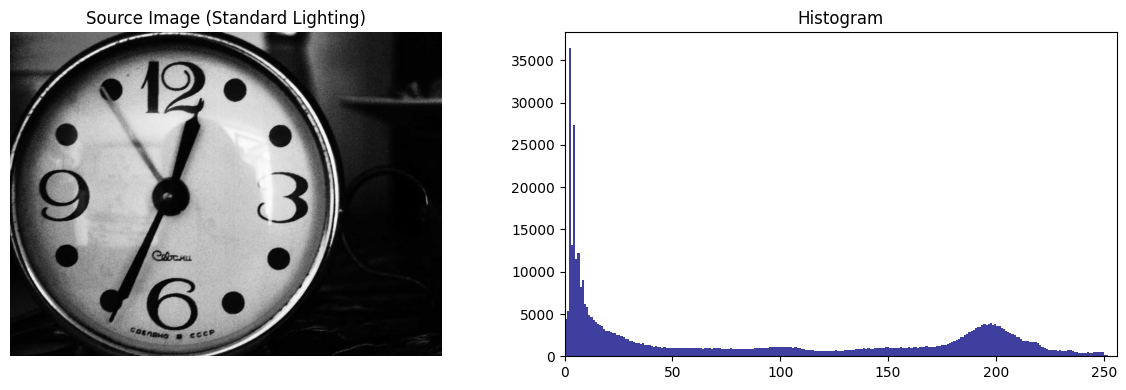

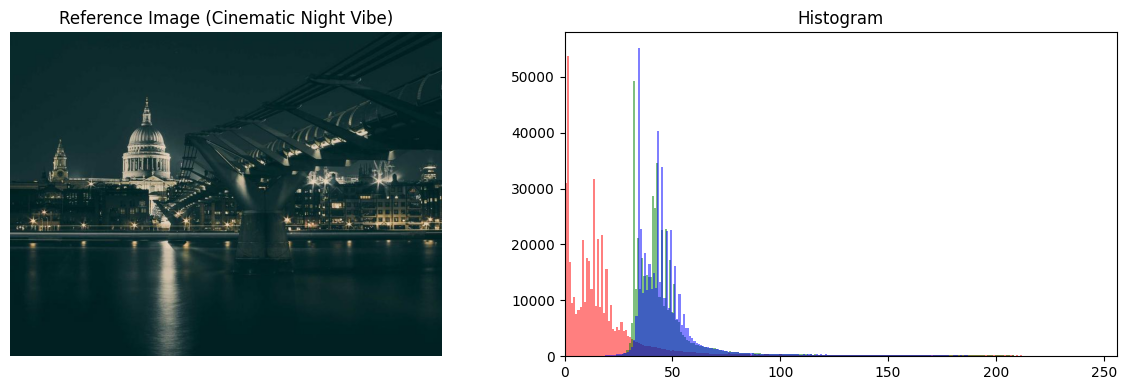

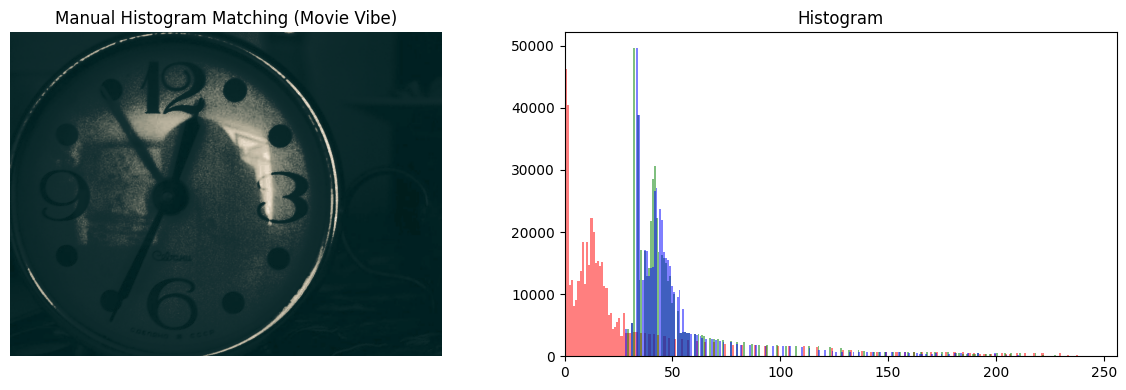

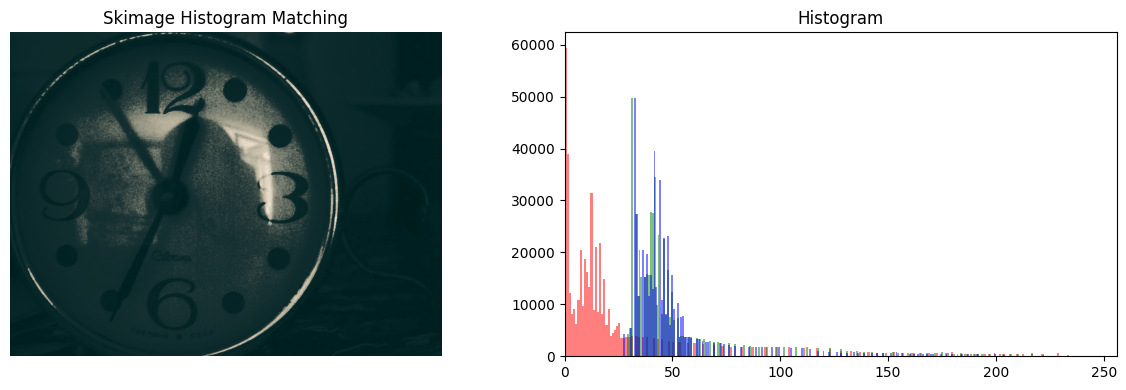

In [ ]:
# Download a standard image (Source) and a stylized image (Reference)
# We use picsum.photos, a developer-friendly image host that won't block Python!

# Source: A standard daylight street/city scene
src_url = "https://picsum.photos/id/175/800/600"
# Reference: A dark, cinematic, cool-toned night city scene
ref_url = "https://picsum.photos/id/122/800/600"

# Because Picsum is developer-friendly, standard io.imread works perfectly
src_img = io.imread(src_url)
ref_img = io.imread(ref_url)

plot_img_and_hist(src_img, "Source Image (Standard Lighting)")
plot_img_and_hist(ref_img, "Reference Image (Cinematic Night Vibe)")

# ==========================================
# 1. MANUAL IMPLEMENTATION (RGB)
# ==========================================
def calculate_cdf(channel):
    hist, _ = np.histogram(channel.flatten(), 256, [0, 256])
    cdf = hist.cumsum()
    cdf_normalized = cdf / float(cdf.max())
    return cdf_normalized

def manual_match_histograms(src, ref):
    matched = np.zeros_like(src)

    # We must match each color channel (R, G, B) independently
    for c in range(src.shape[2]):
        src_channel = src[:, :, c]
        ref_channel = ref[:, :, c]

        # 1. Compute normalized CDFs
        src_cdf = calculate_cdf(src_channel)
        ref_cdf = calculate_cdf(ref_channel)

        # 2. Create the mapping lookup table
        # For every pixel value (0-255) in the source, find the pixel value in
        # the reference that has the closest matching CDF value.
        mapping = np.zeros(256, dtype=np.uint8)
        for src_pixel_val in range(256):
            # Find the index in ref_cdf where the difference is minimized
            closest_match = np.argmin(np.abs(ref_cdf - src_cdf[src_pixel_val]))
            mapping[src_pixel_val] = closest_match

        # 3. Apply the mapping to the source channel
        matched[:, :, c] = mapping[src_channel]

    return matched

img_matched_manual = manual_match_histograms(src_img, ref_img)
plot_img_and_hist(img_matched_manual, "Manual Histogram Matching (Movie Vibe)")

# ==========================================
# 2. SKIMAGE IMPLEMENTATION
# ==========================================
# Note: channel_axis=-1 tells the function to treat the last dimension as color channels
img_matched_skimage = exposure.match_histograms(src_img, ref_img, channel_axis=-1)
plot_img_and_hist(img_matched_skimage, "Skimage Histogram Matching")